# Automotive IDS on CAN traffic: results walkthrough
Reads the outputs of the `src/` pipeline (run the scripts first; see README). Full discussion in `reports/security_report.md`.

In [1]:
import pandas as pd
from IPython.display import Image, display
R = '../reports/'
pd.set_option('display.precision', 4)

## 1. Hybrid detector (whitelist + Isolation Forest v2), per attack

In [2]:
h = pd.read_csv(R + 'results_hybrid.csv')
h[h.detector == 'hybrid'].set_index('attack')

,detector,precision,recall,f1,roc_auc,fpr
attack,,,,,,
DoS,hybrid,0.9283,1.0000,0.9628,1.0000,0.0147
Fuzzy,hybrid,0.9382,0.9917,0.9642,0.9974,0.0096
Gear,hybrid,0.8316,0.9809,0.9001,0.9905,0.0308
RPM,hybrid,0.8285,0.9893,0.9018,0.9899,0.0338


## 2. Ablation: forest only vs rule only vs hybrid
The rule alone dominates DoS/Fuzzy (unseen IDs); the forest is essential for Gear/RPM.

In [3]:
h.pivot(index='attack', columns='detector', values='f1')

detector,forest_only,hybrid,rule_only
attack,,,
DoS,0.0000,0.9628,1.0000
Fuzzy,0.0100,0.9642,0.9926
Gear,0.9001,0.9001,0.0000
RPM,0.9018,0.9018,0.0000


## 3. Baseline (naive features) and detector versions

In [4]:
pd.read_csv(R + 'f1_by_detector.csv', index_col=0)

,IF v1 (naive),IF v2 (directional),IF v2 + ID rule,LSTM + ID rule*
attack,,,,
DoS,0.0002,0.0000,0.9628,0.7542
Fuzzy,0.7577,0.0100,0.9642,0.6749
Gear,0.0332,0.9001,0.9001,0.6156
RPM,0.0224,0.9018,0.9018,0.6608


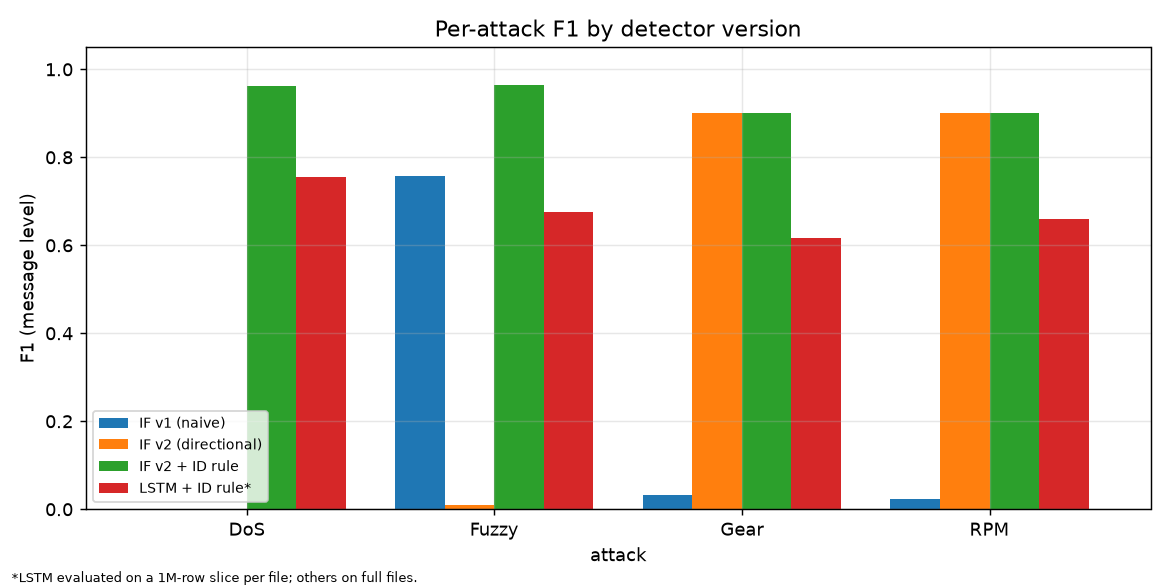

In [5]:
display(Image(R + 'figures/f1_by_detector.png'))

## 4. LSTM vs Isolation Forest (1M-row slices)

In [6]:
l = pd.read_csv(R + 'results_lstm.csv')
l.pivot(index='attack', columns='detector', values='f1')

detector,iforest_hybrid,lstm,lstm+rule
attack,,,
DoS,0.9667,0.7535,0.7542
Fuzzy,0.9679,0.6748,0.6749
Gear,0.9052,0.6156,0.6156
RPM,0.9043,0.6608,0.6608


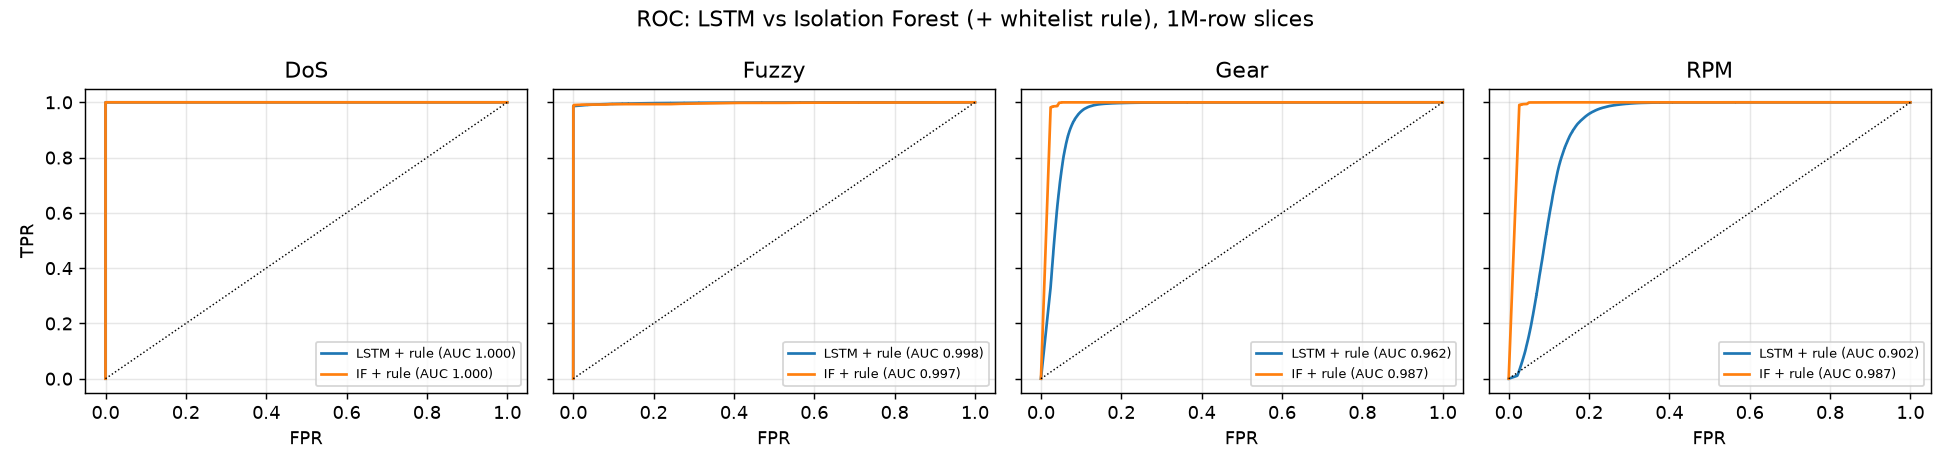

In [7]:
display(Image(R + 'figures/roc_comparison.png'))

## 5. Where do false positives occur?
Far from injections the forest hybrid matches its 0.5% calibration target; errors cluster within about 20 messages of an injection.

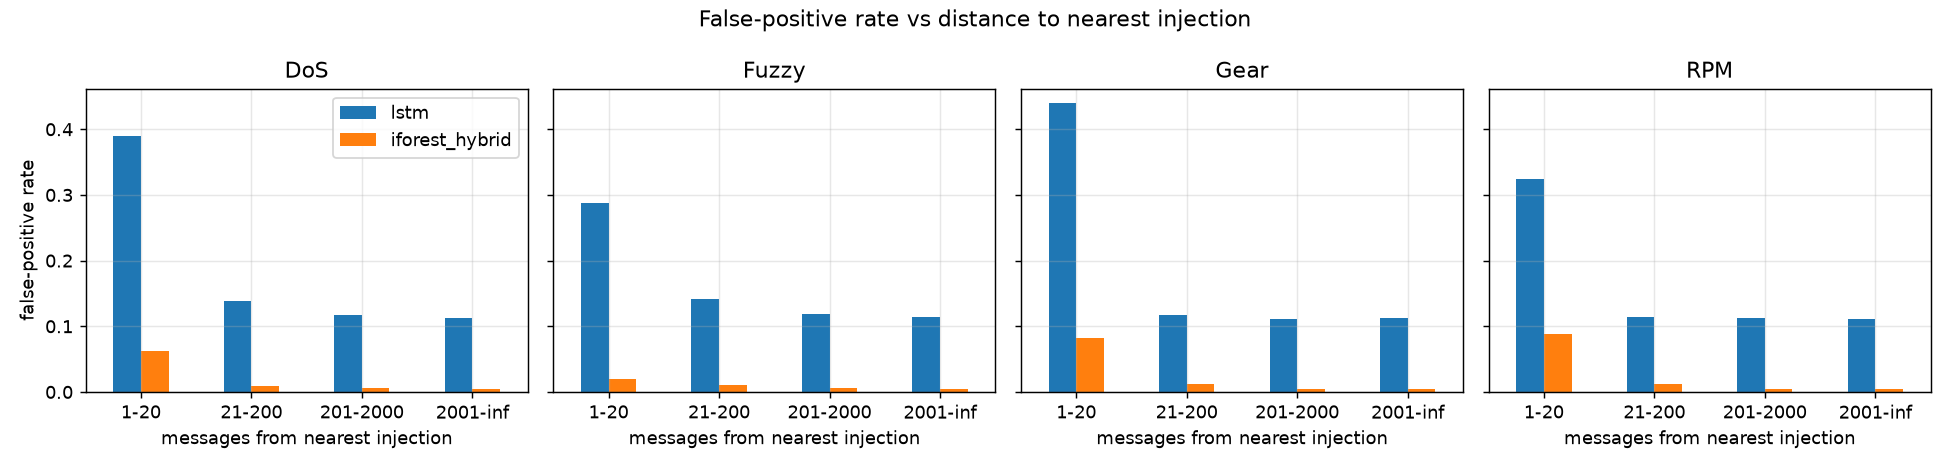

In [8]:
display(Image(R + 'figures/fpr_vs_distance.png'))

In [9]:
pd.read_csv(R + 'quiet_period_fpr.csv')

,attack,quiet_share,lstm_quiet_fpr,if_hybrid_quiet_fpr,if_hybrid_overall_fpr,if_hybrid_burst_fpr
0,DoS,0.7052,0.1158,0.0054,0.0194,0.0529
1,Fuzzy,0.6856,0.1174,0.0054,0.0096,0.0189
2,Gear,0.5084,0.1112,0.0050,0.0405,0.0772
3,RPM,0.4819,0.1126,0.0049,0.0455,0.0833


## 6. Confusion matrices (hybrid)

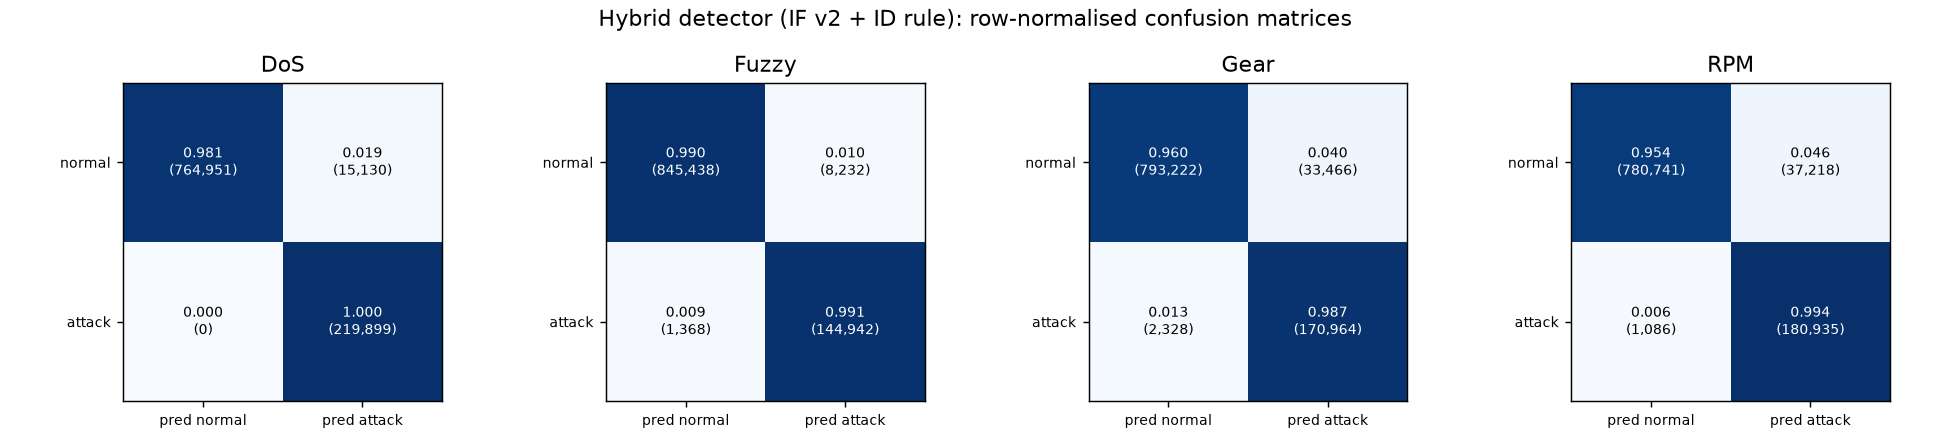

In [10]:
display(Image(R + 'figures/confusion_hybrid.png'))